<a href="https://colab.research.google.com/github/Muktesh9-11/GLOBAL_FDI_NET_INFLOWS_ANALYSIS/blob/main/Global_FDI_Live_API_Analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Global FDI Analysis — Complete Google Colab Project (Live API)

This notebook rebuilds the project **from scratch using live World Bank APIs**. It does not require a preloaded CSV or ZIP dataset.

It downloads country-year indicators, cleans the data, calculates the five selected indicator associations, evaluates why regression is not retained, creates a decision tree and classification analysis, performs descriptive time-series analysis, runs K-means clustering and a paired-period test, and generates the graphs plus a report-ready numerical summary.

**Important:** World Bank data can be revised. If you rerun this notebook later, the latest API values or indicator coverage may differ, so some numbers and graphs can change. The notebook prints the exact results generated by each run.

## 1. Install/import libraries

In [ ]:
!pip -q install requests pandas numpy matplotlib seaborn scipy scikit-learn

import os, time, json, zipfile, warnings
import requests
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from scipy.stats import wilcoxon, spearmanr, pearsonr
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import (
    accuracy_score, confusion_matrix, classification_report,
    ConfusionMatrixDisplay, mean_absolute_error, mean_squared_error, r2_score
)
from sklearn.ensemble import RandomForestRegressor
from sklearn.dummy import DummyRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from IPython.display import display

warnings.filterwarnings("ignore")
RANDOM_STATE = 42
START_YEAR, END_YEAR = 2000, 2025
OUTPUT_DIR = "/content/fdi_project_outputs"
os.makedirs(OUTPUT_DIR, exist_ok=True)

plt.rcParams["figure.dpi"] = 130
sns.set_theme(style="whitegrid")
print("Environment ready.")

Environment ready.


## 2. Define World Bank indicators

In [ ]:
# Target
INDICATORS = {
    "FDI_GDP_pct": "BX.KLT.DINV.WD.GD.ZS",             # FDI net inflows (% of GDP)
    "FDI_USD": "BX.KLT.DINV.CD.WD",                   # FDI net inflows (current US$)

    # Five selected candidate indicators
    "Trade_GDP_pct": "NE.TRD.GNFS.ZS",                # Trade (% of GDP)
    "Population": "SP.POP.TOTL",                      # Total population
    "Domestic_credit_pct_GDP": "FS.AST.PRVT.GD.ZS",   # Domestic credit to private sector (% GDP)
    "Mobile_subscriptions_per_100": "IT.CEL.SETS.P2", # Mobile cellular subscriptions per 100
    "GDP_per_capita_USD": "NY.GDP.PCAP.CD",           # GDP per capita (current US$)

    # Additional context for tree, clusters and descriptive analysis
    "GDP_USD": "NY.GDP.MKTP.CD",
    "GDP_Growth_pct": "NY.GDP.MKTP.KD.ZG",
    "Inflation_pct": "FP.CPI.TOTL.ZG",
    "Internet_users_pct": "IT.NET.USER.ZS",
    "Natural_resource_rents_pct_GDP": "NY.GDP.TOTL.RT.ZS",
    "Gross_capital_formation_pct_GDP": "NE.GDI.FTOT.ZS",
    "Labour_force_participation_pct": "SL.TLF.CACT.ZS",
    "Unemployment_pct": "SL.UEM.TOTL.ZS",
    "Lending_interest_rate_pct": "FR.INR.LEND",
    "Official_exchange_rate": "PA.NUS.FCRF",
}

INDICATOR_LABELS = {
    "FDI_GDP_pct": "FDI net inflows (% of GDP)",
    "Trade_GDP_pct": "Trade openness (% of GDP)",
    "Population": "Population",
    "Domestic_credit_pct_GDP": "Domestic credit to private sector (% of GDP)",
    "Mobile_subscriptions_per_100": "Mobile subscriptions per 100 people",
    "GDP_per_capita_USD": "GDP per capita (current US$)",
    "GDP_Growth_pct": "GDP growth (annual %)",
    "Inflation_pct": "Inflation (annual %)",
    "Internet_users_pct": "Individuals using the Internet (%)",
    "Natural_resource_rents_pct_GDP": "Natural resource rents (% of GDP)",
    "Gross_capital_formation_pct_GDP": "Gross capital formation (% of GDP)",
    "Labour_force_participation_pct": "Labour force participation rate (%)",
    "Unemployment_pct": "Unemployment rate (%)",
    "Lending_interest_rate_pct": "Lending interest rate (%)",
    "Official_exchange_rate": "Official exchange rate (LCU per US$)",
}
print(f"Configured {len(INDICATORS)} World Bank indicators.")

Configured 17 World Bank indicators.


## 3. Download data from the World Bank API

In [ ]:
BASE_URL = "https://api.worldbank.org/v2/country/all/indicator/{indicator}"
session = requests.Session()
session.headers.update({"User-Agent": "FDI-Student-Analysis/1.0"})

def fetch_indicator(indicator_code, start_year=START_YEAR, end_year=END_YEAR, retries=3):
    """Fetch all available country-year rows for one World Bank indicator."""
    url = BASE_URL.format(indicator=indicator_code)
    params = {
        "format": "json",
        "date": f"{start_year}:{end_year}",
        "per_page": 20000,
        "page": 1
    }
    for attempt in range(retries):
        try:
            response = session.get(url, params=params, timeout=60)
            response.raise_for_status()
            payload = response.json()
            if not isinstance(payload, list) or len(payload) < 2 or payload[1] is None:
                return pd.DataFrame(columns=["Country_Code", "Country", "Year", indicator_code])
            meta, records = payload[0], payload[1]
            all_records = list(records or [])
            total_pages = int(meta.get("pages", 1))
            for page in range(2, total_pages + 1):
                params["page"] = page
                page_response = session.get(url, params=params, timeout=60)
                page_response.raise_for_status()
                page_payload = page_response.json()
                all_records.extend(page_payload[1] or [])
                time.sleep(0.05)
            rows = []
            for rec in all_records:
                country_info = rec.get("country") or {}
                rows.append({
                    "Country_Code": (rec.get("countryiso3code") or ""),
                    "Country": country_info.get("value"),
                    "Year": pd.to_numeric(rec.get("date"), errors="coerce"),
                    indicator_code: pd.to_numeric(rec.get("value"), errors="coerce"),
                    "Region": (rec.get("region") or {}).get("value"),
                    "Income_Level": (rec.get("incomeLevel") or {}).get("value"),
                })
            result = pd.DataFrame(rows)
            # World Bank aggregates are not individual countries. Remove aggregate codes where region is "Aggregates".
            if "Region" in result:
                result = result[result["Region"].ne("Aggregates")]
            result = result.dropna(subset=["Year"])
            result["Year"] = result["Year"].astype(int)
            return result
        except Exception as exc:
            if attempt == retries - 1:
                raise RuntimeError(f"Failed to fetch {indicator_code}: {exc}")
            time.sleep(2 ** attempt)

frames = {}
for name, code_ in INDICATORS.items():
    print(f"Downloading {name} ({code_}) ...")
    frames[name] = fetch_indicator(code_)
    print("  rows:", len(frames[name]), "| non-null:", int(frames[name][code_].notna().sum()))

  rows: 6916 | non-null: 6275
  rows: 6916 | non-null: 6384
  rows: 6916 | non-null: 5647
  rows: 6916 | non-null: 6890
  rows: 6916 | non-null: 5286
  rows: 6916 | non-null: 6159
  rows: 6916 | non-null: 6676
  rows: 6916 | non-null: 6676
  rows: 6916 | non-null: 6602
  rows: 6916 | non-null: 5944
  rows: 6916 | non-null: 5572
  rows: 6916 | non-null: 5591
  rows: 6916 | non-null: 5363
  rows: 6916 | non-null: 6096
  rows: 6916 | non-null: 6096
  rows: 6916 | non-null: 3160
  rows: 6916 | non-null: 5391


## 4. Merge indicators into a country-year dataset

In [ ]:

# Start from target FDI/GDP
target_code = INDICATORS["FDI_GDP_pct"]
keys = ["Country_Code", "Year"]
id_cols = ["Country_Code", "Country", "Year", "Region", "Income_Level"]

# Helper: consolidate to one row per country-year
def consolidate_country_year(frame, value_cols):
    frame = frame.copy()

    # Convert year to a consistent numeric type
    frame["Year"] = pd.to_numeric(frame["Year"], errors="coerce")
    frame = frame.dropna(subset=keys)

    # Report duplicate keys before consolidation
    duplicate_count = frame.duplicated(keys, keep=False).sum()
    if duplicate_count:
        print(f"Found {duplicate_count} rows with duplicate country-year keys.")

    # Keep metadata from the first row; average numeric indicators
    aggregations = {}
    for col in value_cols:
        aggregations[col] = "mean"

    for col in ["Country", "Region", "Income_Level"]:
        if col in frame.columns:
            aggregations[col] = "first"

    return frame.groupby(keys, as_index=False).agg(aggregations)


# Consolidate the target dataset
target_frame = frames["FDI_GDP_pct"].rename(
    columns={target_code: "FDI_GDP_pct"}
)

df = consolidate_country_year(
    target_frame[id_cols + ["FDI_GDP_pct"]],
    ["FDI_GDP_pct"]
)

# Merge the remaining indicators
for name, code_ in INDICATORS.items():
    if name == "FDI_GDP_pct":
        continue

    part = frames[name][keys + [code_]].rename(
        columns={code_: name}
    )

    # Ensure one observation per country-year
    part = consolidate_country_year(part, [name])

    df = df.merge(
        part,
        on=keys,
        how="left",
        validate="one_to_one"
    )

# Log transforms for highly skewed size variables
for col in ["Population", "GDP_per_capita_USD", "GDP_USD"]:
    if col in df.columns:
        df.loc[df[col] <= 0, col] = np.nan
        df[f"Log_{col}"] = np.log(df[col])

# Apply the required year range
df = df[
    (df["Year"] >= START_YEAR) &
    (df["Year"] <= END_YEAR)
].copy()

df = (
    df.replace([np.inf, -np.inf], np.nan)
      .sort_values(["Country_Code", "Year"])
      .reset_index(drop=True)
)

print("Merged data shape:", df.shape)
print("Countries/economies:", df["Country_Code"].nunique())
print("Years:", int(df["Year"].min()), "to", int(df["Year"].max()))
print(
    "Remaining duplicate country-year rows:",
    df.duplicated(keys).sum()
)

display(df.head())


Found 130 rows with duplicate country-year keys.
Found 130 rows with duplicate country-year keys.
Found 130 rows with duplicate country-year keys.
Found 130 rows with duplicate country-year keys.
Found 130 rows with duplicate country-year keys.
Found 130 rows with duplicate country-year keys.
Found 130 rows with duplicate country-year keys.
Found 130 rows with duplicate country-year keys.
Found 130 rows with duplicate country-year keys.
Found 130 rows with duplicate country-year keys.
Found 130 rows with duplicate country-year keys.
Found 130 rows with duplicate country-year keys.
Found 130 rows with duplicate country-year keys.
Found 130 rows with duplicate country-year keys.
Found 130 rows with duplicate country-year keys.
Found 130 rows with duplicate country-year keys.
Found 130 rows with duplicate country-year keys.
Merged data shape: (6812, 25)
Countries/economies: 262
Years: 2000 to 2025
Remaining duplicate country-year rows: 0


,Country_Code,Year,FDI_GDP_pct,Country,Region,Income_Level,FDI_USD,Trade_GDP_pct,Population,Domestic_credit_pct_GDP,...,Internet_users_pct,Natural_resource_rents_pct_GDP,Gross_capital_formation_pct_GDP,Labour_force_participation_pct,Unemployment_pct,Lending_interest_rate_pct,Official_exchange_rate,Log_Population,Log_GDP_per_capita_USD,Log_GDP_USD
0,,2000,2.682004,High income,None,None,3.923528e+11,43.883346,1.540382e+09,61.388734,...,NaN,6.362886,23.566188,65.078532,6.048169,NaN,NaN,21.155296,8.744622,29.769938
1,,2001,2.450172,High income,None,None,2.239237e+11,42.859553,1.561185e+09,57.266174,...,NaN,5.692892,24.085799,64.882073,6.070081,NaN,NaN,21.168711,8.730841,29.763485
2,,2002,2.200706,High income,None,None,1.879233e+11,45.724352,1.581793e+09,57.813788,...,NaN,5.643871,23.869428,64.719482,6.233749,NaN,NaN,21.181825,8.765339,29.801312
3,,2003,2.247078,High income,None,None,1.842206e+11,47.548545,1.602338e+09,60.125710,...,NaN,6.456121,24.443680,64.582406,6.279036,NaN,NaN,21.194730,8.873800,29.915515
4,,2004,2.358408,High income,None,None,2.523228e+11,51.423667,1.623089e+09,60.366594,...,NaN,7.096131,25.267638,64.495517,6.121240,NaN,NaN,21.207597,8.983291,30.034790


## 5. Data quality and descriptive statistics

In [ ]:
quality = pd.DataFrame({
    "Missing_Count": df.isna().sum(),
    "Missing_Percent": (df.isna().mean() * 100).round(2),
    "Non_Missing_Count": df.notna().sum()
}).sort_values("Missing_Percent", ascending=False)
display(quality)

print("FDI/GDP descriptive statistics:")
display(df["FDI_GDP_pct"].describe().to_frame("FDI_GDP_pct").round(3))

# Save clean country-year data for reuse, if desired.
df.to_csv(os.path.join(OUTPUT_DIR, "world_bank_fdi_country_year_data.csv"), index=False)

,Missing_Count,Missing_Percent,Non_Missing_Count
Region,6812,100.00,0
Income_Level,6812,100.00,0
Lending_interest_rate_pct,3652,53.61,3160
Domestic_credit_pct_GDP,1595,23.41,5217
Gross_capital_formation_pct_GDP,1514,22.23,5298
Official_exchange_rate,1421,20.86,5391
Internet_users_pct,1303,19.13,5509
Natural_resource_rents_pct_GDP,1287,18.89,5525
Trade_GDP_pct,1242,18.23,5570
Inflation_pct,946,13.89,5866


FDI/GDP descriptive statistics:


,FDI_GDP_pct
count,6197.000
mean,7.597
std,53.877
min,-1303.108
25%,1.226
50%,2.606
75%,5.013
max,1709.827


## 6. Global annual FDI time series

,Year,Median_FDI_GDP_pct,Mean_FDI_GDP_pct,Q1,Q3,Observations
0,2000,2.577,7.280,0.962,5.278,232
1,2001,2.499,5.257,0.922,4.245,233
2,2002,2.439,4.440,0.923,4.041,234
3,2003,2.308,6.111,0.997,3.892,235
4,2004,2.567,4.651,1.204,5.424,235
5,2005,2.873,5.965,1.484,5.629,236
6,2006,3.749,14.741,1.999,7.307,237
7,2007,4.495,14.051,2.480,8.727,239
8,2008,3.812,9.823,2.420,7.927,240
9,2009,2.710,10.592,1.417,5.602,240


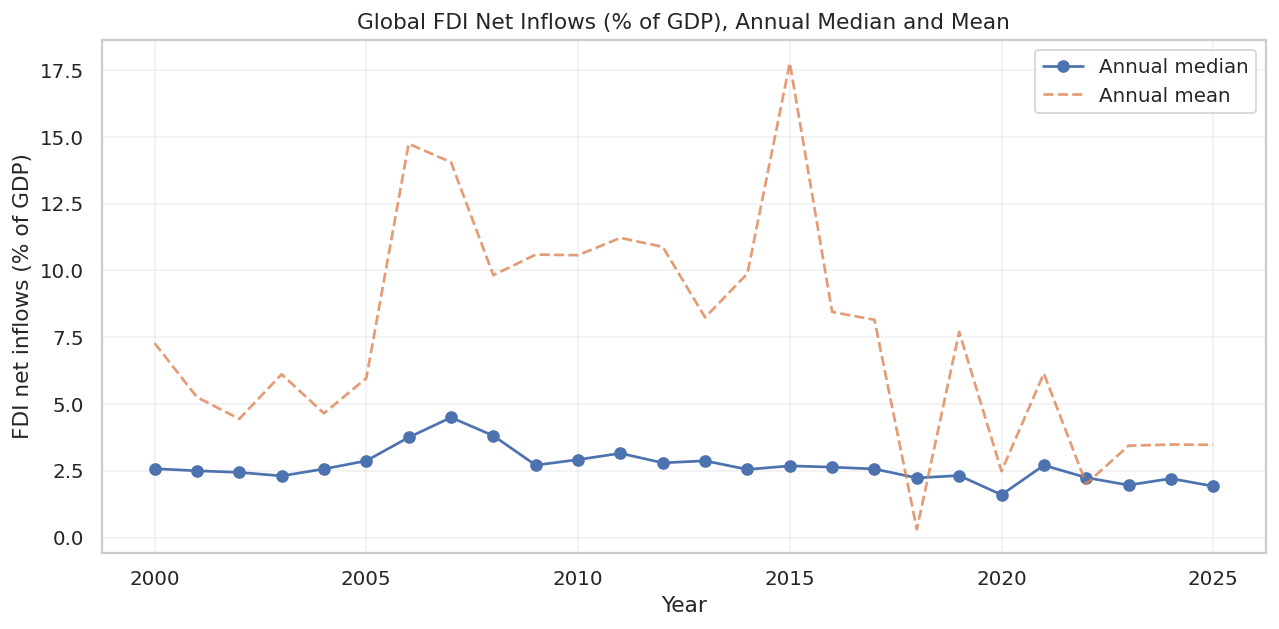

First available year median: 2000 = 2.577%
Last available year median: 2025 = 1.921%
Highest annual median: 2007 = 4.495%
Lowest annual median: 2020 = 1.601%


In [ ]:
annual = (
    df.dropna(subset=["FDI_GDP_pct"])
      .groupby("Year")["FDI_GDP_pct"]
      .agg(Median_FDI_GDP_pct="median", Mean_FDI_GDP_pct="mean",
           Q1=lambda x: x.quantile(.25), Q3=lambda x: x.quantile(.75),
           Observations="count")
      .reset_index()
)
display(annual.round(3))

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(annual["Year"], annual["Median_FDI_GDP_pct"], marker="o", label="Annual median")
ax.plot(annual["Year"], annual["Mean_FDI_GDP_pct"], linestyle="--", alpha=.8, label="Annual mean")
ax.set_title("Global FDI Net Inflows (% of GDP), Annual Median and Mean")
ax.set_xlabel("Year")
ax.set_ylabel("FDI net inflows (% of GDP)")
ax.legend()
ax.grid(alpha=.25)
fig.tight_layout()
fig.savefig(os.path.join(OUTPUT_DIR, "01_global_fdi_time_series.png"), bbox_inches="tight")
plt.show()

maxrow = annual.loc[annual["Median_FDI_GDP_pct"].idxmax()]
minrow = annual.loc[annual["Median_FDI_GDP_pct"].idxmin()]
firstrow, lastrow = annual.iloc[0], annual.iloc[-1]
print(f"First available year median: {int(firstrow.Year)} = {firstrow.Median_FDI_GDP_pct:.3f}%")
print(f"Last available year median: {int(lastrow.Year)} = {lastrow.Median_FDI_GDP_pct:.3f}%")
print(f"Highest annual median: {int(maxrow.Year)} = {maxrow.Median_FDI_GDP_pct:.3f}%")
print(f"Lowest annual median: {int(minrow.Year)} = {minrow.Median_FDI_GDP_pct:.3f}%")

## 7. Analyze the five selected factors

Five candidate indicators: ['Trade openness', 'Log population', 'Domestic credit', 'Mobile subscriptions', 'Log GDP per capita']
Rows with target and each indicator are assessed pairwise; missing data means sample sizes differ.


Period,2001–2005,2006–2010,2011–2015,2016–2020,2021–2025
Indicator,,,,,
Domestic credit,0.249,0.224,0.108,0.098,0.073
Log GDP per capita,0.240,0.206,0.050,0.138,0.081
Log population,-0.158,-0.310,-0.262,-0.237,-0.266
Mobile subscriptions,0.332,0.225,0.151,0.189,0.174
Trade openness,0.396,0.458,0.345,0.341,0.327


,Period,Indicator,Column,Correlation,N
0,2001–2005,Trade openness,Trade_GDP_pct,0.396,985
1,2001–2005,Log population,Log_Population,-0.158,1173
2,2001–2005,Domestic credit,Domestic_credit_pct_GDP,0.249,922
3,2001–2005,Mobile subscriptions,Mobile_subscriptions_per_100,0.332,1161
4,2001–2005,Log GDP per capita,Log_GDP_per_capita_USD,0.240,1173
5,2006–2010,Trade openness,Trade_GDP_pct,0.458,1014
6,2006–2010,Log population,Log_Population,-0.310,1195
7,2006–2010,Domestic credit,Domestic_credit_pct_GDP,0.224,1025
8,2006–2010,Mobile subscriptions,Mobile_subscriptions_per_100,0.225,1180
9,2006–2010,Log GDP per capita,Log_GDP_per_capita_USD,0.206,1195


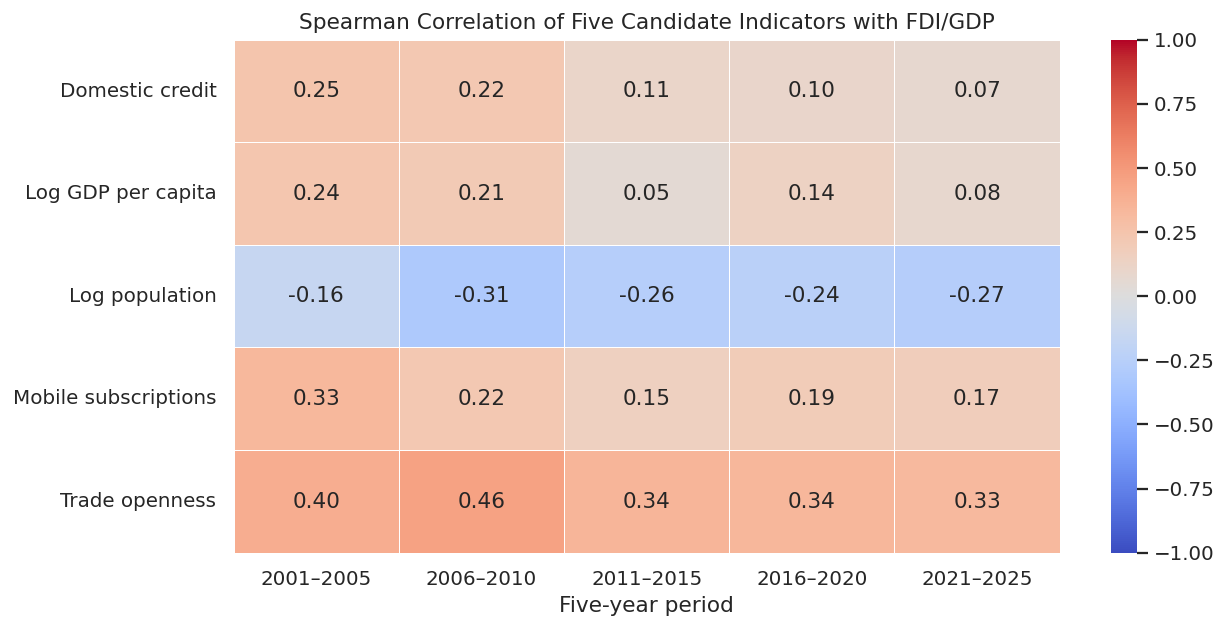

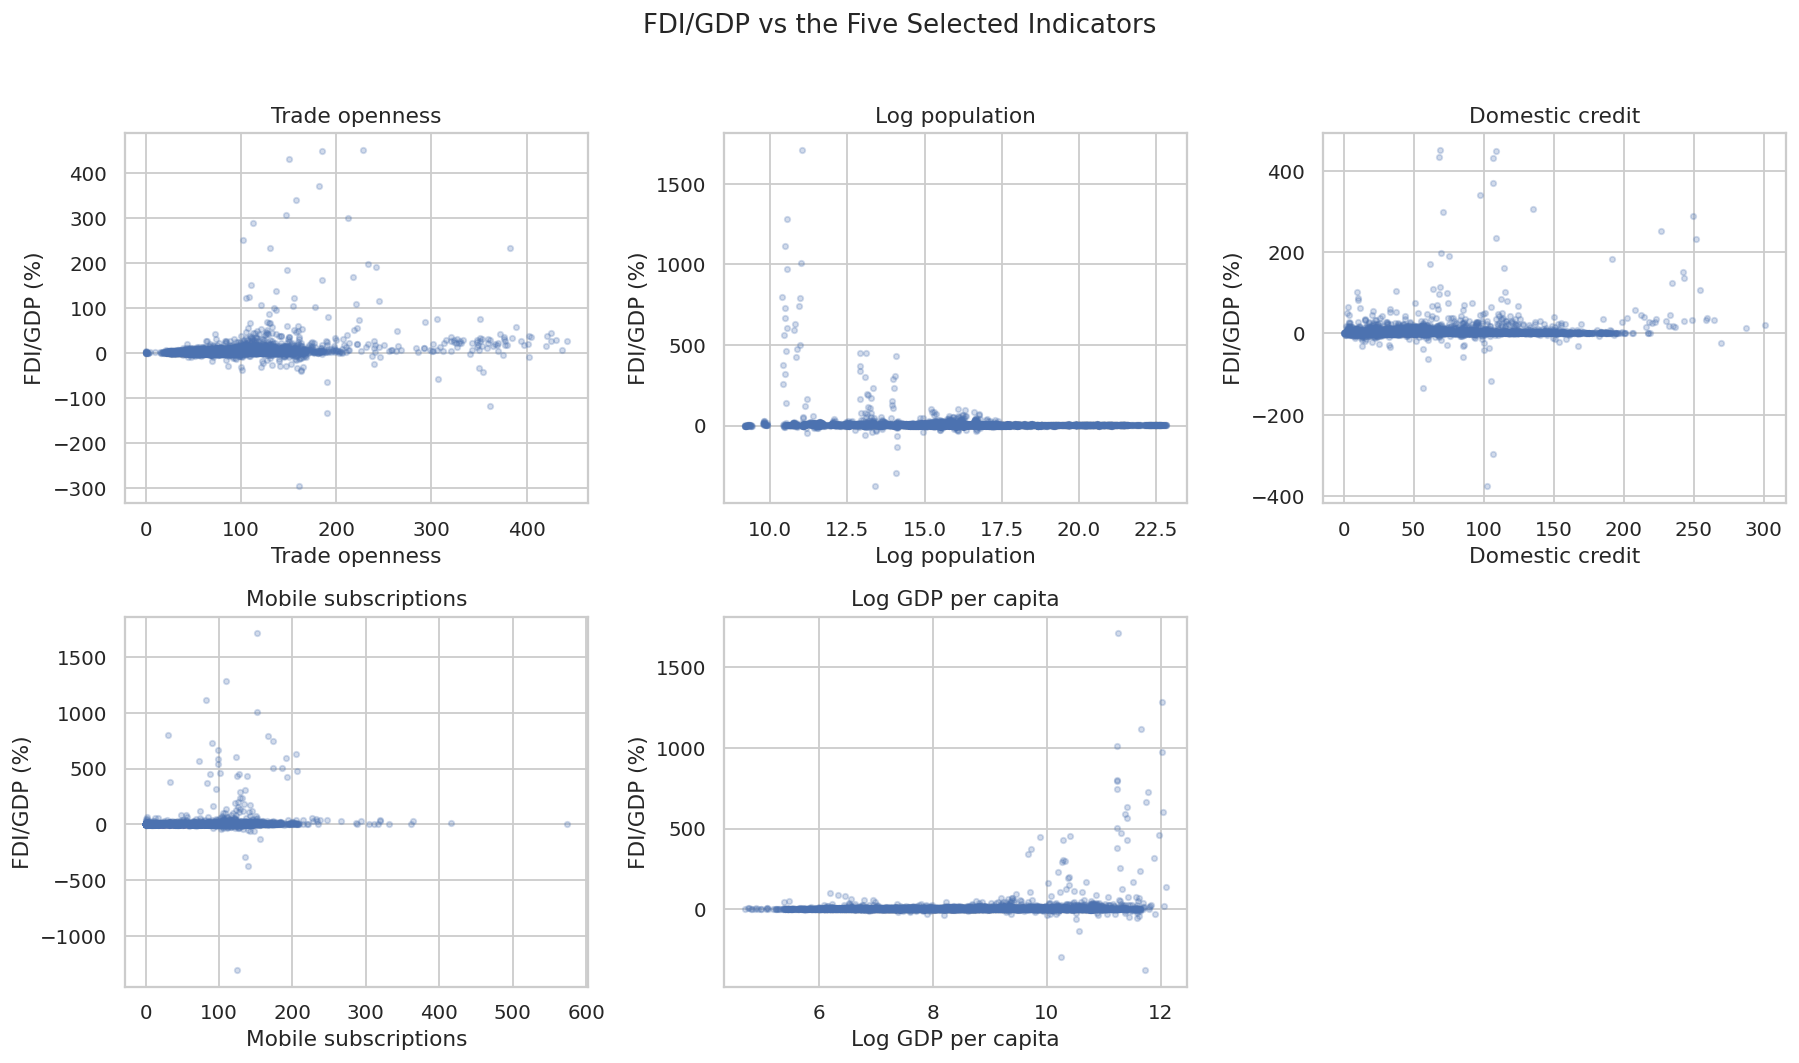

Interpretation guidance: report the direction, approximate strength, period-to-period stability, and sample size.
Correlation indicates association, not causation.


In [ ]:
TOP5 = [
    "Trade_GDP_pct",
    "Log_Population",
    "Domestic_credit_pct_GDP",
    "Mobile_subscriptions_per_100",
    "Log_GDP_per_capita_USD",
]
pretty_names = {
    "Trade_GDP_pct": "Trade openness",
    "Log_Population": "Log population",
    "Domestic_credit_pct_GDP": "Domestic credit",
    "Mobile_subscriptions_per_100": "Mobile subscriptions",
    "Log_GDP_per_capita_USD": "Log GDP per capita",
}
available_top5 = [c for c in TOP5 if c in df.columns]
print("Five candidate indicators:", [pretty_names[c] for c in TOP5])
print("Rows with target and each indicator are assessed pairwise; missing data means sample sizes differ.")

def corr_by_period(data, columns, method="spearman", start=2001, end=2025, width=5):
    rows = []
    for period_start in range(start, end + 1, width):
        period_end = min(period_start + width - 1, end)
        sub = data[(data["Year"] >= period_start) & (data["Year"] <= period_end)]
        for col in columns:
            if col not in sub.columns:
                continue
            pair = sub[["FDI_GDP_pct", col]].dropna()
            if len(pair) < 3 or pair[col].nunique() < 2 or pair["FDI_GDP_pct"].nunique() < 2:
                r = np.nan
            else:
                if method == "spearman":
                    r = pair["FDI_GDP_pct"].corr(pair[col], method="spearman")
                else:
                    r = pair["FDI_GDP_pct"].corr(pair[col], method="pearson")
            rows.append({
                "Period": f"{period_start}–{period_end}",
                "Indicator": pretty_names.get(col, col),
                "Column": col,
                "Correlation": r,
                "N": len(pair)
            })
    return pd.DataFrame(rows)

corr_spearman = corr_by_period(df, TOP5, method="spearman", start=2001, end=2025, width=5)
corr_pearson = corr_by_period(df, TOP5, method="pearson", start=2001, end=2025, width=5)
display(corr_spearman.pivot(index="Indicator", columns="Period", values="Correlation").round(3))
display(corr_spearman.round(3))

corr_spearman.to_csv(os.path.join(OUTPUT_DIR, "top5_spearman_correlations_by_period.csv"), index=False)
corr_pearson.to_csv(os.path.join(OUTPUT_DIR, "top5_pearson_correlations_by_period.csv"), index=False)

pivot = corr_spearman.pivot(index="Indicator", columns="Period", values="Correlation")
fig, ax = plt.subplots(figsize=(10, 5))
sns.heatmap(pivot, annot=True, fmt=".2f", center=0, vmin=-1, vmax=1,
            cmap="coolwarm", linewidths=.5, ax=ax)
ax.set_title("Spearman Correlation of Five Candidate Indicators with FDI/GDP")
ax.set_xlabel("Five-year period")
ax.set_ylabel("")
fig.tight_layout()
fig.savefig(os.path.join(OUTPUT_DIR, "02_top_five_correlation_segments.png"), bbox_inches="tight")
plt.show()

# Scatter plots of the five candidate indicators against FDI/GDP
fig, axes = plt.subplots(2, 3, figsize=(14, 8))
for ax, col in zip(axes.flat, TOP5):
    if col not in df.columns:
        ax.set_visible(False)
        continue
    sub = df[[col, "FDI_GDP_pct"]].dropna()
    # Sample for legibility only; correlations above use all available rows
    if len(sub) > 5000:
        sub = sub.sample(5000, random_state=RANDOM_STATE)
    ax.scatter(sub[col], sub["FDI_GDP_pct"], alpha=.25, s=9)
    ax.set_title(pretty_names[col])
    ax.set_xlabel(pretty_names[col])
    ax.set_ylabel("FDI/GDP (%)")
axes.flat[-1].set_visible(False)
fig.suptitle("FDI/GDP vs the Five Selected Indicators", y=1.02)
fig.tight_layout()
fig.savefig(os.path.join(OUTPUT_DIR, "03_top_five_scatterplots.png"), bbox_inches="tight")
plt.show()

print("Interpretation guidance: report the direction, approximate strength, period-to-period stability, and sample size.")
print("Correlation indicates association, not causation.")

## 8. Regression comparison — brief evidence only

In [ ]:
# This section is deliberately brief: it compares the Top 5 / Top 7 / all available predictors
# and explains why regression prediction is not retained as the main project result.
# Use lagged predictors (year t-1) to explain FDI/GDP in year t, then hold out later years.

reg_df = df.sort_values(["Country_Code", "Year"]).copy()
predictor_base = [
    "Trade_GDP_pct", "Log_Population", "Domestic_credit_pct_GDP",
    "Mobile_subscriptions_per_100", "Log_GDP_per_capita_USD",
    "Log_GDP_USD", "GDP_Growth_pct", "Inflation_pct", "Internet_users_pct",
    "Natural_resource_rents_pct_GDP", "Gross_capital_formation_pct_GDP",
    "Labour_force_participation_pct", "Unemployment_pct", "Lending_interest_rate_pct",
    "Official_exchange_rate"
]
predictor_base = [c for c in predictor_base if c in reg_df.columns]
for c in predictor_base:
    reg_df[c + "_lag1"] = reg_df.groupby("Country_Code")[c].shift(1)

reg_df["Target_Year"] = reg_df["Year"]
reg_df = reg_df.dropna(subset=["FDI_GDP_pct"])
train = reg_df[reg_df["Target_Year"] <= 2018].copy()
test = reg_df[(reg_df["Target_Year"] >= 2019) & (reg_df["Target_Year"] <= 2024)].copy()

def evaluate_rf_feature_set(label, features):
    features = [c for c in features if c in reg_df.columns]
    if not features:
        return None
    tr = train.dropna(subset=["FDI_GDP_pct"])
    te = test.dropna(subset=["FDI_GDP_pct"])
    # Keep a common test population with at least one observed feature; imputer fills remaining gaps.
    tr = tr[tr[features].notna().any(axis=1)]
    te = te[te[features].notna().any(axis=1)]
    if len(tr) < 50 or len(te) < 20:
        return {"Model": label, "Features": len(features), "MAE": np.nan, "RMSE": np.nan, "R2": np.nan, "N_test": len(te)}
    model = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("rf", RandomForestRegressor(n_estimators=300, min_samples_leaf=5, random_state=RANDOM_STATE, n_jobs=-1))
    ])
    model.fit(tr[features], tr["FDI_GDP_pct"])
    pred = model.predict(te[features])
    return {"Model": label, "Features": len(features),
            "MAE": mean_absolute_error(te["FDI_GDP_pct"], pred),
            "RMSE": mean_squared_error(te["FDI_GDP_pct"], pred) ** .5,
            "R2": r2_score(te["FDI_GDP_pct"], pred), "N_test": len(te)}

top5_lag = [c + "_lag1" for c in TOP5 if c in df.columns]
top7_names = TOP5 + ["Gross_capital_formation_pct_GDP", "Natural_resource_rents_pct_GDP"]
top7_lag = [c + "_lag1" for c in top7_names if c in df.columns]
all_lag = [c + "_lag1" for c in predictor_base]
trade_only = ["Trade_GDP_pct_lag1"]

# A median baseline for context
results = []
for label, features in [
    ("Top 5 candidates", top5_lag),
    ("Top 7 candidates", top7_lag),
    ("All available predictors", all_lag),
    ("Trade only", trade_only)
]:
    res = evaluate_rf_feature_set(label, features)
    if res is not None:
        results.append(res)

display(pd.DataFrame(results).round(4))
print("Interpretation: negative R² means the model did worse than predicting the test-set mean.")
print("Do not claim FDI is inherently impossible to predict; conclude only that these tested models/features did not predict it reliably.")

,Model,Features,MAE,RMSE,R2,N_test
0,Top 5 candidates,5,6.8395,26.9637,-0.1318,1440
1,Top 7 candidates,7,6.9086,26.7820,-0.1166,1440
2,All available predictors,15,8.5272,28.3090,-0.2476,1440
3,Trade only,1,7.1496,27.2294,-0.0632,1272


Interpretation: negative R² means the model did worse than predicting the test-set mean.
Do not claim FDI is inherently impossible to predict; conclude only that these tested models/features did not predict it reliably.


## 9. Decision tree classification of lower vs higher FDI

Training-period median cutoff: 2.799% GDP
Features used: ['Trade_GDP_pct', 'Log_Population', 'Domestic_credit_pct_GDP', 'Mobile_subscriptions_per_100', 'Log_GDP_per_capita_USD']
Train rows: 4,528; test rows: 1,669
Test accuracy: 0.639 (63.9%)
              precision    recall  f1-score   support

   Lower FDI       0.79      0.57      0.66      1038
  Higher FDI       0.52      0.75      0.61       631

    accuracy                           0.64      1669
   macro avg       0.65      0.66      0.64      1669
weighted avg       0.68      0.64      0.64      1669



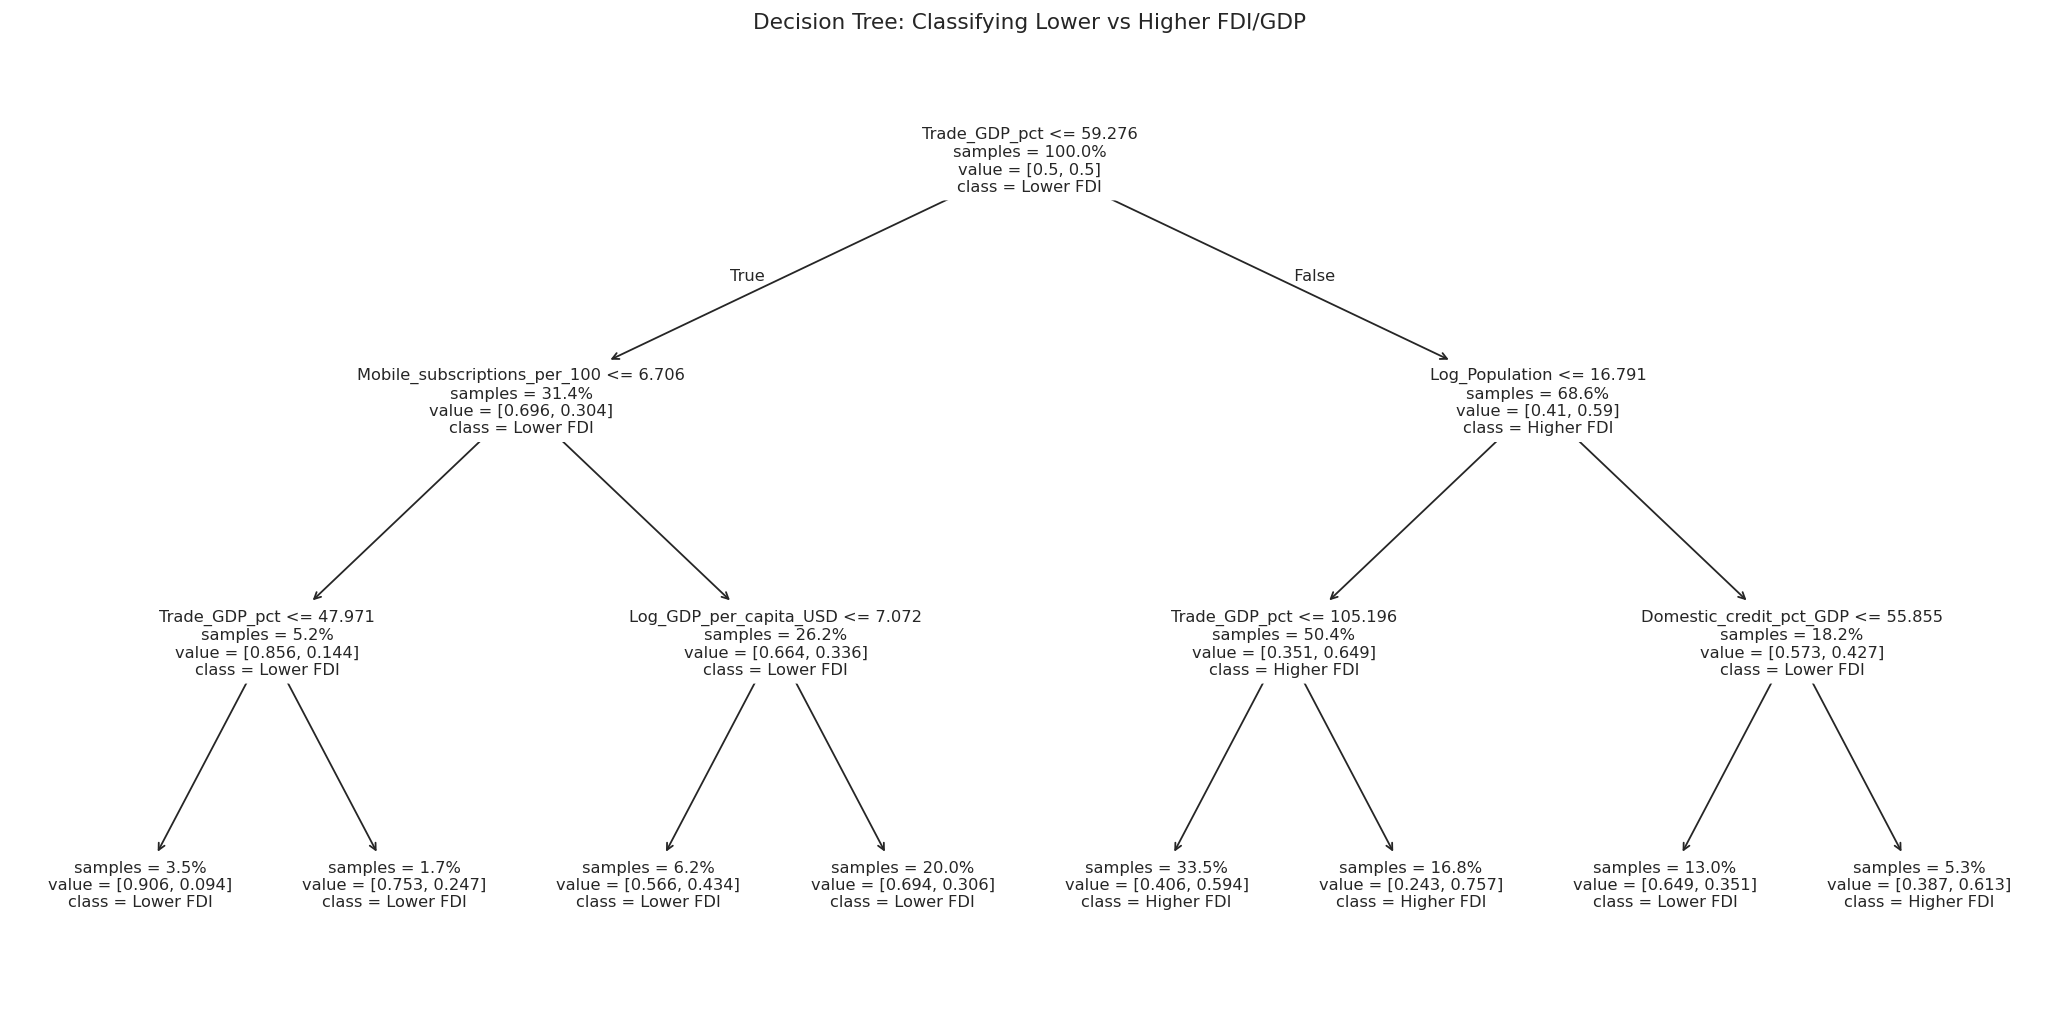

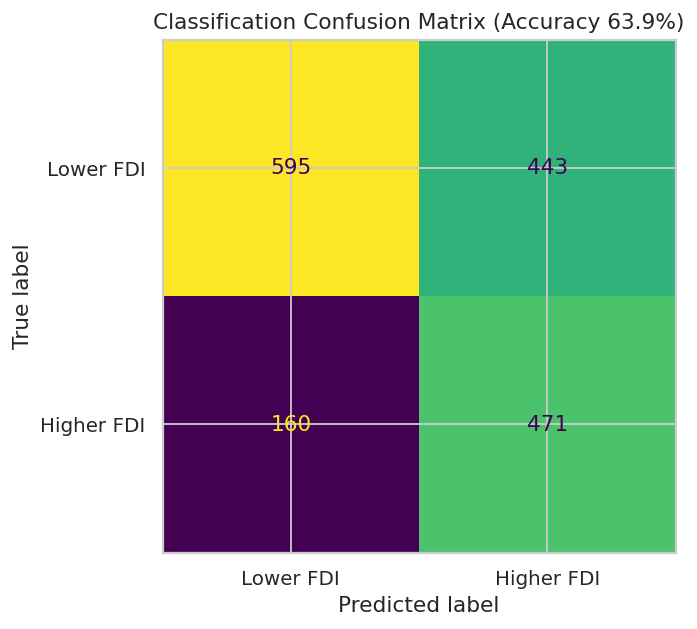

In [ ]:
# Binary target threshold is based on the training period to avoid using test outcomes to define the cutoff.
classification_features = TOP5.copy()
classification_features = [c for c in classification_features if c in df.columns]
class_df = df[["Country_Code", "Year", "FDI_GDP_pct"] + classification_features].replace([np.inf, -np.inf], np.nan)
class_df = class_df.dropna(subset=["FDI_GDP_pct"]).copy()

train_c = class_df[class_df["Year"] <= 2018].copy()
test_c = class_df[class_df["Year"] >= 2019].copy()
class_cutoff = train_c["FDI_GDP_pct"].median()
train_c["FDI_Class"] = (train_c["FDI_GDP_pct"] > class_cutoff).astype(int)
test_c["FDI_Class"] = (test_c["FDI_GDP_pct"] > class_cutoff).astype(int)

# Median-impute each feature, then fit a shallow, interpretable tree.
tree_model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("tree", DecisionTreeClassifier(max_depth=3, min_samples_leaf=40,
                                    random_state=RANDOM_STATE, class_weight="balanced"))
])
tree_model.fit(train_c[classification_features], train_c["FDI_Class"])
pred_c = tree_model.predict(test_c[classification_features])
accuracy = accuracy_score(test_c["FDI_Class"], pred_c)
cm = confusion_matrix(test_c["FDI_Class"], pred_c, labels=[0,1])

print(f"Training-period median cutoff: {class_cutoff:.3f}% GDP")
print(f"Features used: {classification_features}")
print(f"Train rows: {len(train_c):,}; test rows: {len(test_c):,}")
print(f"Test accuracy: {accuracy:.3f} ({accuracy:.1%})")
print(classification_report(test_c["FDI_Class"], pred_c,
                            labels=[0,1], target_names=["Lower FDI", "Higher FDI"], zero_division=0))

fig, ax = plt.subplots(figsize=(16, 8))
plot_tree(tree_model.named_steps["tree"], feature_names=classification_features,
          class_names=["Lower FDI", "Higher FDI"], filled=False, rounded=True,
          impurity=False, proportion=True, fontsize=9, ax=ax)
ax.set_title("Decision Tree: Classifying Lower vs Higher FDI/GDP")
fig.tight_layout()
fig.savefig(os.path.join(OUTPUT_DIR, "04_decision_tree.png"), bbox_inches="tight")
plt.show()

disp = ConfusionMatrixDisplay(cm, display_labels=["Lower FDI", "Higher FDI"])
fig, ax = plt.subplots(figsize=(6,5))
disp.plot(ax=ax, values_format="d", colorbar=False)
ax.set_title(f"Classification Confusion Matrix (Accuracy {accuracy:.1%})")
fig.tight_layout()
fig.savefig(os.path.join(OUTPUT_DIR, "05_classification_confusion_matrix.png"), bbox_inches="tight")
plt.show()

## 10. K-means clustering: descriptive country profiles

Countries in clustering: 206
Silhouette score (3 clusters): 0.299


,Cluster,FDI_GDP_pct,GDP_Growth_pct,Inflation_pct,Trade_GDP_pct,Internet_users_pct
0,0,2.760,4.569,6.727,66.584,20.502
1,1,6.127,2.786,2.662,112.175,63.011
2,2,426.427,2.998,1.189,115.978,69.466


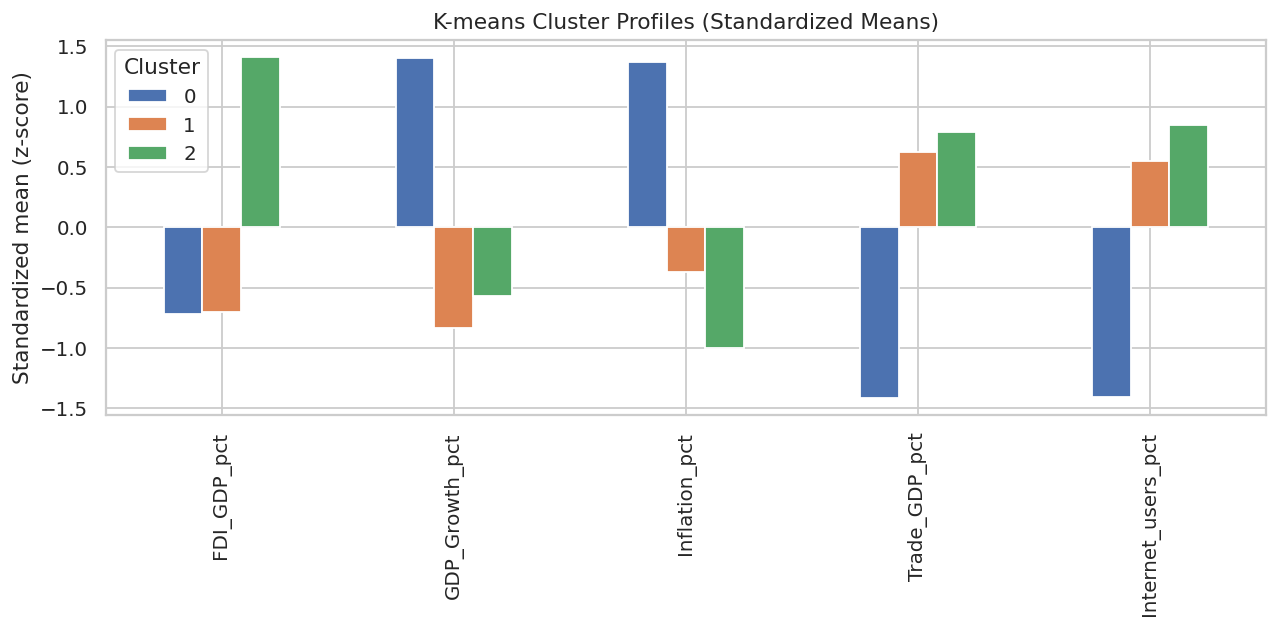

In [ ]:
cluster_features = ["FDI_GDP_pct", "GDP_Growth_pct", "Inflation_pct",
                    "Trade_GDP_pct", "Internet_users_pct"]
cluster_data = df[["Country_Code", "Country", "Year"] + cluster_features].copy()
# Average each country across the available years to create one profile per country.
country_profiles = cluster_data.groupby(["Country_Code", "Country"])[cluster_features].median().dropna()
# Use complete country profiles so cluster interpretation is clear.
scaler = StandardScaler()
X_scaled = scaler.fit_transform(country_profiles)
kmeans = KMeans(n_clusters=3, random_state=RANDOM_STATE, n_init=20)
country_profiles["Cluster"] = kmeans.fit_predict(X_scaled)
sil = silhouette_score(X_scaled, country_profiles["Cluster"]) if country_profiles["Cluster"].nunique() > 1 else np.nan
cluster_means = country_profiles.groupby("Cluster")[cluster_features].mean().reset_index()
print("Countries in clustering:", len(country_profiles))
print(f"Silhouette score (3 clusters): {sil:.3f}")
display(cluster_means.round(3))

profile_z = (cluster_means.set_index("Cluster")[cluster_features] -
             cluster_means[cluster_features].mean()) / cluster_means[cluster_features].std(ddof=0)
fig, ax = plt.subplots(figsize=(10, 5))
profile_z.T.plot(kind="bar", ax=ax)
ax.set_title("K-means Cluster Profiles (Standardized Means)")
ax.set_ylabel("Standardized mean (z-score)")
ax.set_xlabel("")
ax.legend(title="Cluster")
fig.tight_layout()
fig.savefig(os.path.join(OUTPUT_DIR, "06_cluster_profiles.png"), bbox_inches="tight")
plt.show()

country_profiles.reset_index().to_csv(os.path.join(OUTPUT_DIR, "country_clusters.csv"), index=False)

## 11. Paired before/after period comparison

Countries with both-period data: 241
Median post-minus-pre difference: -0.485 percentage points
Mean post-minus-pre difference: -3.189 percentage points
Wilcoxon signed-rank statistic: 8648.0; p-value: 4.354e-08


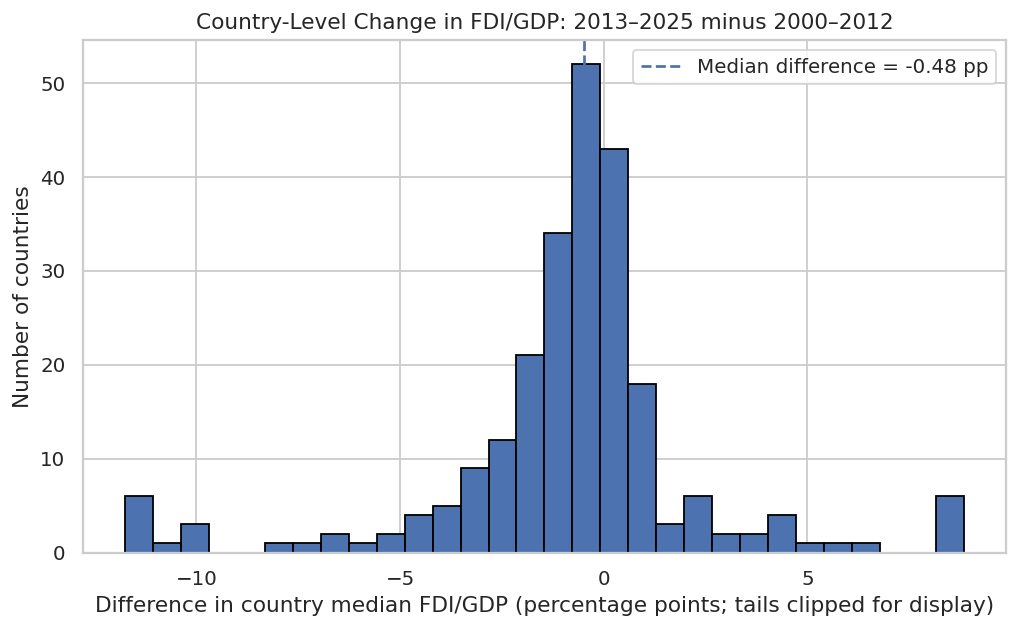

In [ ]:
# Compare median FDI/GDP per country in 2000–2012 vs 2013–2025.
# Pair only countries that have data in both periods.
pre = df[df["Year"].between(2000, 2012)].groupby("Country_Code")["FDI_GDP_pct"].median().rename("Pre")
post = df[df["Year"].between(2013, 2025)].groupby("Country_Code")["FDI_GDP_pct"].median().rename("Post")
paired = pd.concat([pre, post], axis=1).dropna()
paired["Difference_Post_minus_Pre"] = paired["Post"] - paired["Pre"]
diff = paired["Difference_Post_minus_Pre"]

print("Countries with both-period data:", len(paired))
print(f"Median post-minus-pre difference: {diff.median():.3f} percentage points")
print(f"Mean post-minus-pre difference: {diff.mean():.3f} percentage points")
try:
    stat, pvalue = wilcoxon(diff)
    print(f"Wilcoxon signed-rank statistic: {stat:.1f}; p-value: {pvalue:.4g}")
except Exception as e:
    stat, pvalue = np.nan, np.nan
    print("Wilcoxon test unavailable:", e)

lo, hi = diff.quantile([.02, .98])
fig, ax = plt.subplots(figsize=(8, 5))
ax.hist(diff.clip(lo, hi), bins=30, edgecolor="black")
ax.axvline(diff.median(), linestyle="--", label=f"Median difference = {diff.median():.2f} pp")
ax.set_title("Country-Level Change in FDI/GDP: 2013–2025 minus 2000–2012")
ax.set_xlabel("Difference in country median FDI/GDP (percentage points; tails clipped for display)")
ax.set_ylabel("Number of countries")
ax.legend()
fig.tight_layout()
fig.savefig(os.path.join(OUTPUT_DIR, "07_period_difference.png"), bbox_inches="tight")
plt.show()

## 12. Generate report-ready results and limitations

In [ ]:
# Compact text report with results generated from THIS API run.
corr_text = corr_spearman.copy()
corr_text["Correlation"] = corr_text["Correlation"].round(3)
lines = []
lines.append("GLOBAL FDI ANALYSIS — REPORT-READY SUMMARY")
lines.append("=" * 48)
lines.append(f"API retrieval date: {pd.Timestamp.now().strftime('%Y-%m-%d')}")
lines.append(f"Data rows: {len(df):,}; country/economy codes: {df['Country_Code'].nunique()}; years: {int(df.Year.min())}–{int(df.Year.max())}")
lines.append("")
lines.append("TIME SERIES")
lines.append(f"First available annual median: {int(firstrow.Year)} = {firstrow.Median_FDI_GDP_pct:.3f}%")
lines.append(f"Last available annual median: {int(lastrow.Year)} = {lastrow.Median_FDI_GDP_pct:.3f}%")
lines.append(f"Highest annual median: {int(maxrow.Year)} = {maxrow.Median_FDI_GDP_pct:.3f}%")
lines.append(f"Lowest annual median: {int(minrow.Year)} = {minrow.Median_FDI_GDP_pct:.3f}%")
lines.append("")
lines.append("FIVE INDICATOR SPEARMAN CORRELATIONS (each period's available sample)")
lines.append(corr_text.pivot(index="Indicator", columns="Period", values="Correlation").to_string())
lines.append("")
lines.append("REGRESSION NOTE")
lines.append("Use the table printed in the regression section. If R² is negative, the model performed worse than the test-set mean baseline.")
lines.append("This supports the conclusion that the tested predictors/models did not reliably predict FDI/GDP; it does not prove FDI is inherently unpredictable.")
lines.append("")
lines.append("CLASSIFICATION")
lines.append(f"Median cutoff from training period: {class_cutoff:.3f}% GDP")
lines.append(f"Test accuracy: {accuracy:.3f} ({accuracy:.1%}); train rows={len(train_c)}, test rows={len(test_c)}")
lines.append("")
lines.append("CLUSTERING")
lines.append(f"Country profiles={len(country_profiles)}; k=3; silhouette score={sil:.3f}")
lines.append(cluster_means.round(3).to_string(index=False))
lines.append("")
lines.append("PERIOD COMPARISON")
lines.append(f"Paired countries={len(paired)}; median difference={diff.median():.3f} pp; mean difference={diff.mean():.3f} pp; Wilcoxon p={pvalue:.4g}")
lines.append("")
lines.append("LIMITATIONS")
lines.append("- World Bank values are revised; results may change on rerun.")
lines.append("- Indicator coverage differs; each correlation uses available paired observations.")
lines.append("- Correlation is not causation.")
lines.append("- FDI/GDP can contain extreme positive/negative values.")
lines.append("- The classification is a broad high/low grouping, not an investment recommendation.")
report_text = "\n".join(lines)
print(report_text)
with open(os.path.join(OUTPUT_DIR, "report_ready_results.txt"), "w", encoding="utf-8") as f:
    f.write(report_text)
corr_spearman.to_csv(os.path.join(OUTPUT_DIR, "top5_spearman_correlations_by_period.csv"), index=False)
corr_pearson.to_csv(os.path.join(OUTPUT_DIR, "top5_pearson_correlations_by_period.csv"), index=False)
annual.to_csv(os.path.join(OUTPUT_DIR, "annual_fdi_trend.csv"), index=False)

GLOBAL FDI ANALYSIS — REPORT-READY SUMMARY
API retrieval date: 2026-10-11
Data rows: 6,812; country/economy codes: 262; years: 2000–2025

TIME SERIES
First available annual median: 2000 = 2.577%
Last available annual median: 2025 = 1.921%
Highest annual median: 2007 = 4.495%
Lowest annual median: 2020 = 1.601%

FIVE INDICATOR SPEARMAN CORRELATIONS (each period's available sample)
Period                2001–2005  2006–2010  2011–2015  2016–2020  2021–2025
Indicator                                                                  
Domestic credit           0.249      0.224      0.108      0.098      0.073
Log GDP per capita        0.240      0.206      0.050      0.138      0.081
Log population           -0.158     -0.310     -0.262     -0.237     -0.266
Mobile subscriptions      0.332      0.225      0.151      0.189      0.174
Trade openness            0.396      0.458      0.345      0.341      0.327

REGRESSION NOTE
Use the table printed in the regression section. If R² is negative, 

MEAN BASELINE VS TRADE ONLY.

Training observations: 3672
Testing observations: 1272

Prediction results:
                   Model    MAE    RMSE      R2
Trade-only Random Forest 7.1496 27.2294 -0.0632
           Mean baseline 6.9196 26.4482 -0.0031


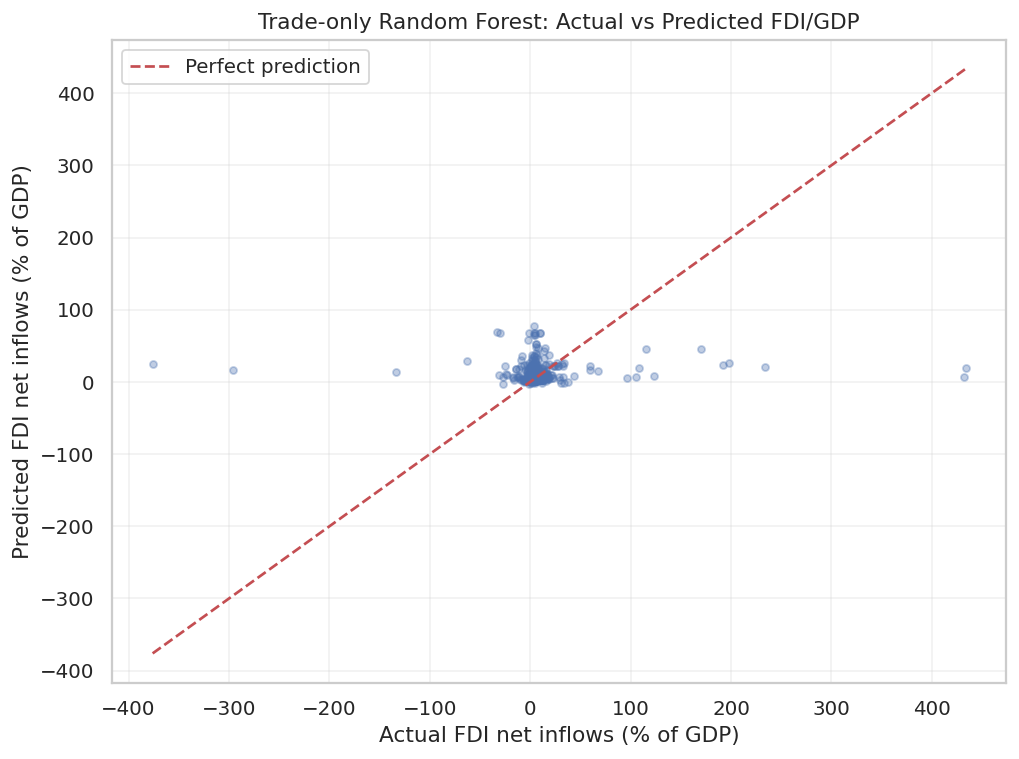

In [ ]:

import numpy as np
import pandas as pd

from sklearn.ensemble import RandomForestRegressor
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# 1. Prepare data and create a one-year lag for trade openness
data = df.sort_values(["Country_Code", "Year"]).copy()

data["Trade_GDP_pct_lag1"] = (
    data.groupby("Country_Code")["Trade_GDP_pct"].shift(1)
)

# Keep the target years used in the previous experiment
data = data.replace([np.inf, -np.inf], np.nan)
data = data.dropna(subset=["FDI_GDP_pct"])

train = data[data["Year"] <= 2018].copy()
test = data[data["Year"].between(2019, 2024)].copy()

feature = ["Trade_GDP_pct_lag1"]
target = "FDI_GDP_pct"

# 2. Use the same eligible observations for both models
train = train.dropna(subset=feature + [target])
test = test.dropna(subset=feature + [target])

X_train = train[feature]
y_train = train[target]
X_test = test[feature]
y_test = test[target]

print("Training observations:", len(train))
print("Testing observations:", len(test))

# 3. Trade-only Random Forest
trade_model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("model", RandomForestRegressor(
        n_estimators=300,
        min_samples_leaf=5,
        random_state=42,
        n_jobs=-1
    ))
])

trade_model.fit(X_train, y_train)
trade_pred = trade_model.predict(X_test)

# 4. Mean baseline on the SAME training and test observations
baseline = DummyRegressor(strategy="mean")
baseline.fit(X_train, y_train)
baseline_pred = baseline.predict(X_test)

# 5. Evaluate both models
def evaluate(name, actual, predicted):
    return {
        "Model": name,
        "MAE": mean_absolute_error(actual, predicted),
        "RMSE": np.sqrt(mean_squared_error(actual, predicted)),
        "R2": r2_score(actual, predicted)
    }

results = pd.DataFrame([
    evaluate("Trade-only Random Forest", y_test, trade_pred),
    evaluate("Mean baseline", y_test, baseline_pred)
])

print("\nPrediction results:")
print(results.round(4).to_string(index=False))

# 6. Plot actual vs predicted FDI/GDP
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 6))
plt.scatter(y_test, trade_pred, alpha=0.35, s=15)
limits = [
    min(y_test.min(), trade_pred.min()),
    max(y_test.max(), trade_pred.max())
]
plt.plot(limits, limits, "r--", label="Perfect prediction")
plt.xlabel("Actual FDI net inflows (% of GDP)")
plt.ylabel("Predicted FDI net inflows (% of GDP)")
plt.title("Trade-only Random Forest: Actual vs Predicted FDI/GDP")
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()


## 13. Download all graphs, data and report-ready numbers

In [ ]:
archive_path = "/content/FDI_Live_API_Analysis_Results.zip"
with zipfile.ZipFile(archive_path, "w", zipfile.ZIP_DEFLATED) as z:
    for root, dirs, filenames in os.walk(OUTPUT_DIR):
        for filename in filenames:
            full_path = os.path.join(root, filename)
            z.write(full_path, arcname=os.path.relpath(full_path, OUTPUT_DIR))

print("Created:", archive_path)
files.download(archive_path)

Created: /content/FDI_Live_API_Analysis_Results.zip


NameError: name 'files' is not defined

In [ ]:
from google.colab import files

files.download("/content/FDI_Live_API_Analysis_Results.zip")